# Twitch Streamers: EDA, Regression Models, and Huber Robust Regression

## Project objective
Explore relationships among Twitch channel activity/popularity metrics and predict **Average viewers**. Compare a baseline Linear Regression model with Random Forest, Gradient Boosting, XGBoost, and Huber Robust Regression.

**Dataset:** `twitchdata-update.csv` (1,000 channels)

### Modelling decisions
- **Target:** `Average viewers`
- **Predictors:** `Watch time(Minutes)`, `Stream time(minutes)`, `Peak viewers`, `Followers`, `Followers gained`, and `Views gained`
- Exclude `Channel` because it is an identifier, and exclude `Language`, `Mature`, and `Partnered` as specified for this project.
- Use an 80:20 train-test split with `random_state=42`.
- Fit preprocessing only on training data. Standardize predictors inside the Huber pipeline; tree-based models do not require standardization.
- Keep all observations in the primary analysis. IQR flags are used to inspect potential outliers, not automatically delete them.


In [11]:
# If running in Google Colab, uncomment the next two lines and upload the CSV when prompted.
# from google.colab import files
# uploaded = files.upload()

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, HuberRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, median_absolute_error

RANDOM_STATE = 42
DATA_PATH = "twitchdata-update.csv"

# If the CSV is not in the current notebook folder, change DATA_PATH to its full path.
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
print("\nMissing values:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))

Shape: (1000, 11)


,Channel,Watch time(Minutes),Stream time(minutes),Peak viewers,Average viewers,Followers,Followers gained,Views gained,Partnered,Mature,Language
0,xQcOW,6196161750,215250,222720,27716,3246298,1734810,93036735,True,False,English
1,summit1g,6091677300,211845,310998,25610,5310163,1370184,89705964,True,False,English
2,Gaules,5644590915,515280,387315,10976,1767635,1023779,102611607,True,True,Portuguese
3,ESL_CSGO,3970318140,517740,300575,7714,3944850,703986,106546942,True,False,English
4,Tfue,3671000070,123660,285644,29602,8938903,2068424,78998587,True,False,English



Missing values: 0
Exact duplicate rows: 0


### Interpretation
The dataset contains 1,000 Twitch channels and 11 columns. `Channel` identifies a channel rather than measuring its performance, so it is not used as a numeric predictor. The analysis focuses on six numeric predictors and `Average viewers` as the response. The missing-value and duplicate checks below help verify whether cleaning is required before modelling.

In [12]:
# Select the target and predictors
target = "Average viewers"
features = [
    "Watch time(Minutes)",
    "Stream time(minutes)",
    "Peak viewers",
    "Followers",
    "Followers gained",
    "Views gained",
]

model_df = df[features + [target]].copy()
for col in features + [target]:
    model_df[col] = pd.to_numeric(model_df[col], errors="coerce")
model_df = model_df.dropna().reset_index(drop=True)

print("Rows available for modelling:", len(model_df))
display(model_df.describe().T.round(2))

Rows available for modelling: 1000


,count,mean,std,min,25%,50%,75%,max
Watch time(Minutes),1000.0,4.184279e+08,5.496355e+08,122192850.0,1.631899e+08,234990787.5,4.337399e+08,6.196162e+09
Stream time(minutes),1000.0,1.205152e+05,8.537620e+04,3465.0,7.375875e+04,108240.0,1.418438e+05,5.214450e+05
Peak viewers,1000.0,3.706505e+04,6.031431e+04,496.0,9.113750e+03,16676.0,3.756975e+04,6.393750e+05
Followers,1000.0,5.700541e+05,8.044134e+05,3660.0,1.705462e+05,318063.0,6.243322e+05,8.938903e+06
Followers gained,1000.0,2.055185e+05,3.399137e+05,-15772.0,4.375825e+04,98352.0,2.361308e+05,3.966525e+06
Views gained,1000.0,1.166817e+07,2.490572e+07,175788.0,3.880602e+06,6456323.5,1.219676e+07,6.701375e+08
Average viewers,1000.0,4.781040e+03,8.453680e+03,235.0,1.457750e+03,2425.0,4.786250e+03,1.476430e+05


### Interpretation
The descriptive statistics summarize typical values and spread. For highly popular channels, activity and audience metrics can vary by several orders of magnitude, so means can be much larger than medians. This is a reason to inspect distributions and extreme observations before choosing and evaluating models.

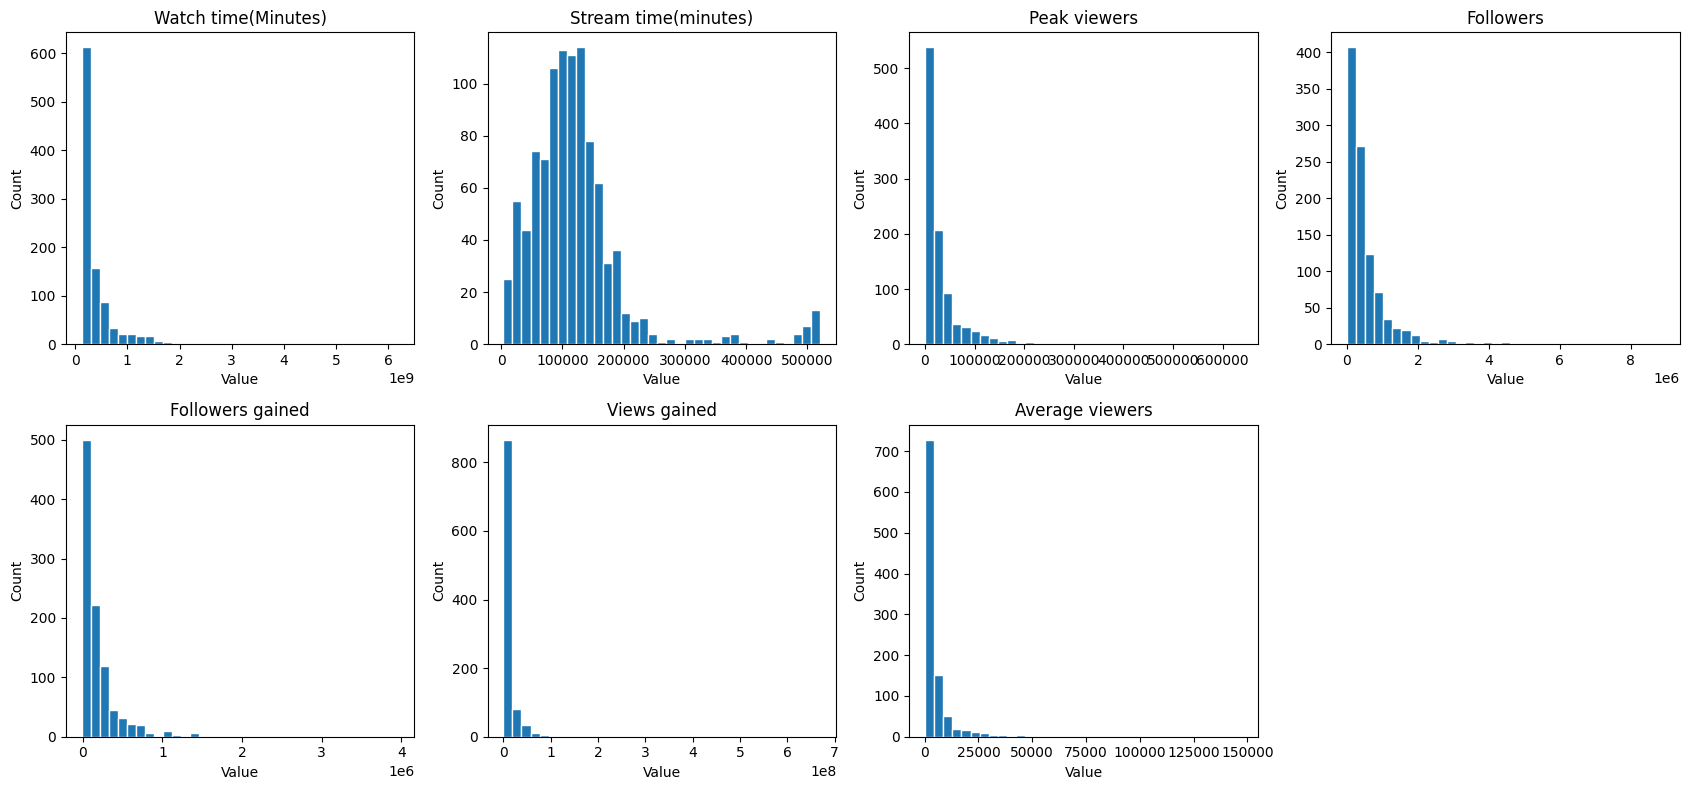

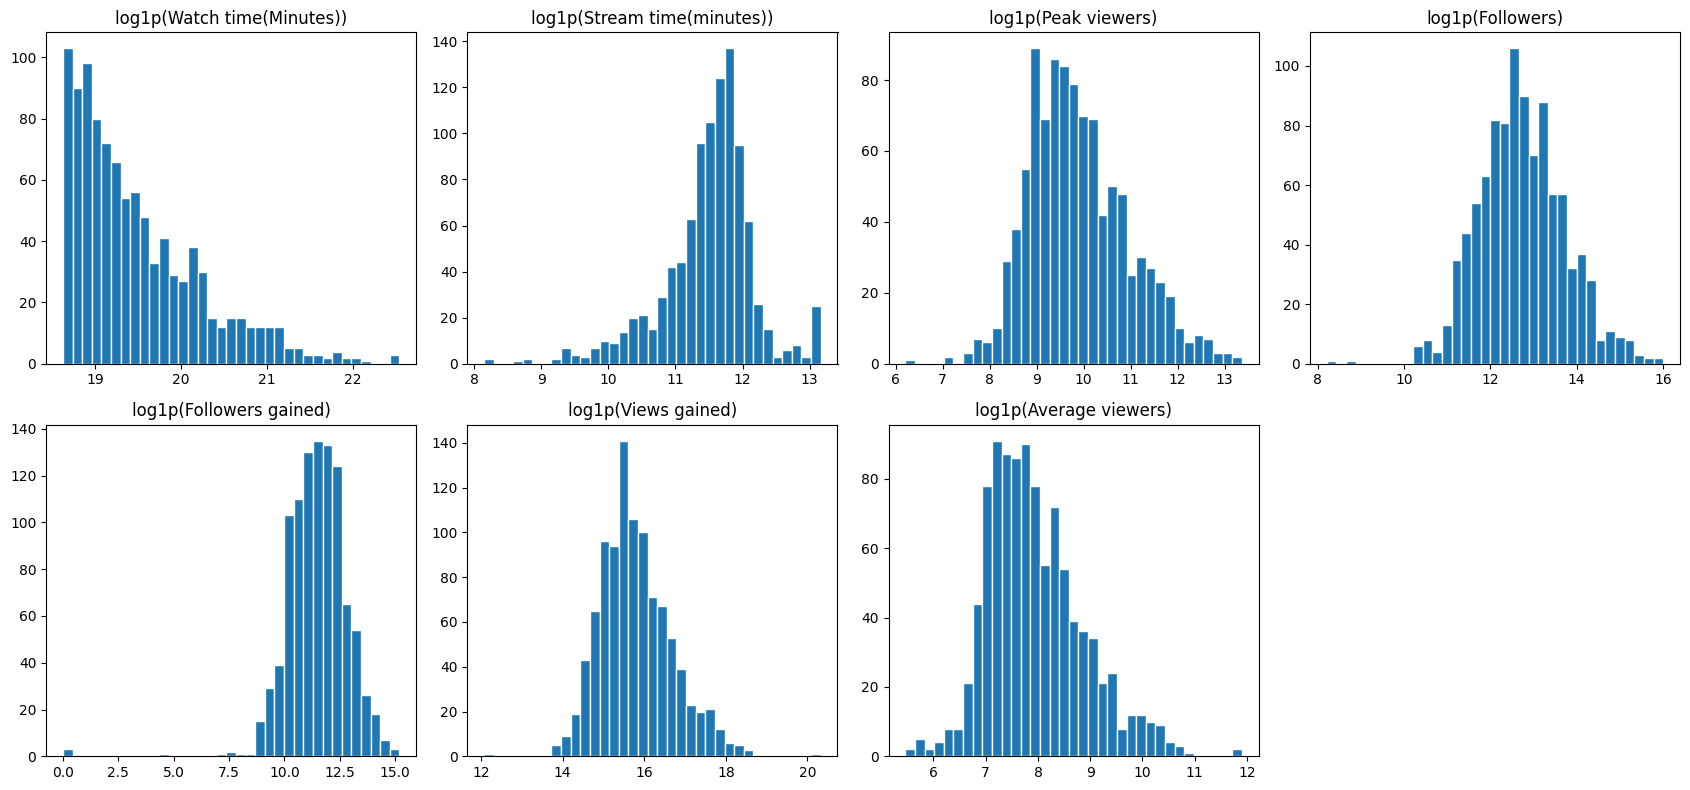

In [13]:
# Distributions: raw scale and log1p scale for readability
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
axes = axes.ravel()
for i, col in enumerate(features + [target]):
    axes[i].hist(model_df[col], bins=35, edgecolor="white")
    axes[i].set_title(col)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Count")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(17, 8))
axes = axes.ravel()
for i, col in enumerate(features + [target]):
    axes[i].hist(np.log1p(model_df[col].clip(lower=0)), bins=35, edgecolor="white")
    axes[i].set_title(f"log1p({col})")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

### Interpretation
The raw-scale histograms show whether a small number of very large channels dominate the scale. The `log1p` plots are for visualization only; the models below use the original target scale. A long right tail suggests that metrics such as watch time, followers, and viewers are not symmetrically distributed. Large values are not automatically data errors—they may represent genuinely popular channels.

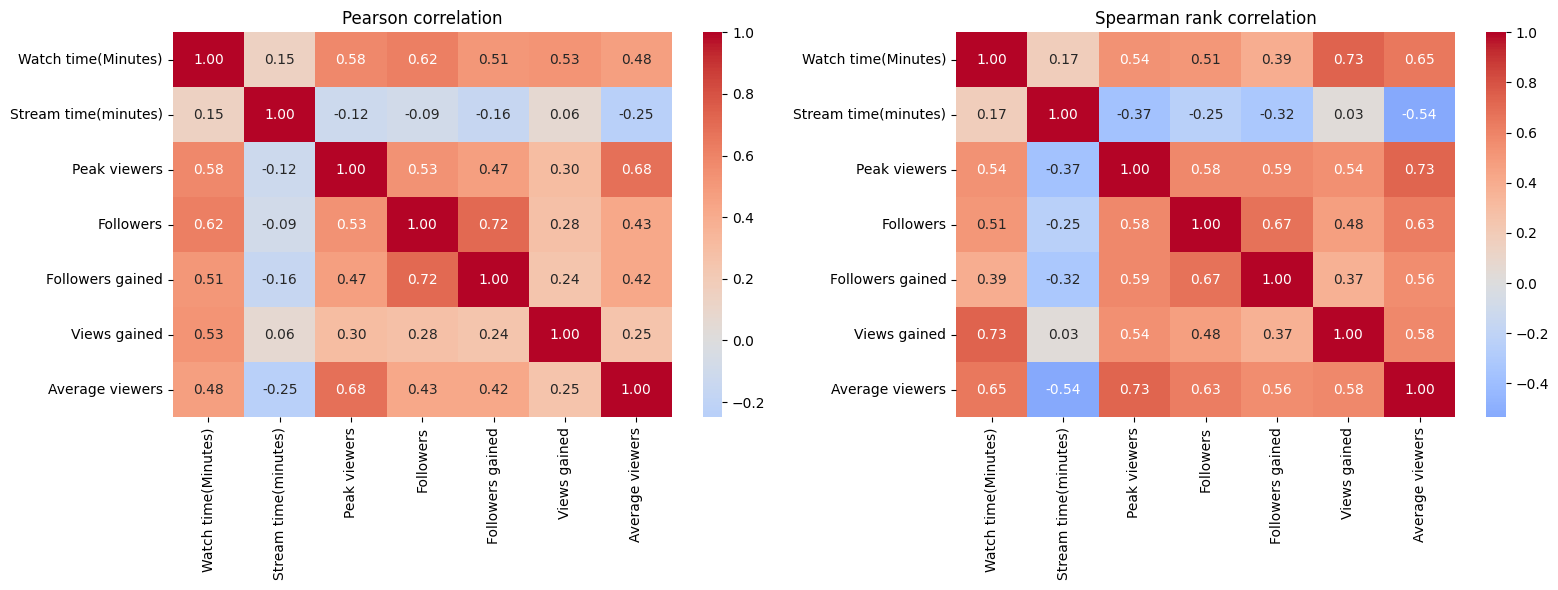

Pearson correlation with Average viewers:


,Pearson r
Peak viewers,0.682637
Watch time(Minutes),0.476165
Followers,0.428303
Followers gained,0.420097
Views gained,0.250349
Stream time(minutes),-0.249248


Spearman correlation with Average viewers:


,Spearman rho
Peak viewers,0.728015
Watch time(Minutes),0.649473
Followers,0.627701
Views gained,0.579129
Followers gained,0.557659
Stream time(minutes),-0.535159


In [14]:
# Pearson and Spearman correlation heatmaps
pearson_corr = model_df.corr(method="pearson")
spearman_corr = model_df.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(pearson_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Pearson correlation")
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Spearman rank correlation")
plt.tight_layout()
plt.show()

print("Pearson correlation with Average viewers:")
display(pearson_corr[target].drop(target).sort_values(key=abs, ascending=False).to_frame("Pearson r"))
print("Spearman correlation with Average viewers:")
display(spearman_corr[target].drop(target).sort_values(key=abs, ascending=False).to_frame("Spearman rho"))

### Interpretation
Pearson correlation measures linear association and can be sensitive to extreme values. Spearman correlation measures monotonic association using ranks and is often more robust to skewed scales. Strong correlations among predictors may indicate overlapping information; correlation alone does not establish causality. These plots guide interpretation but do not determine which model will predict best.

Rows flagged in at least one of the 7 numeric columns: 288 / 1000
Rows flagged by target Average viewers alone: 100


,Rows flagged by column
Peak viewers,113
Watch time(Minutes),107
Average viewers,100
Views gained,91
Followers gained,90
Followers,89
Stream time(minutes),48


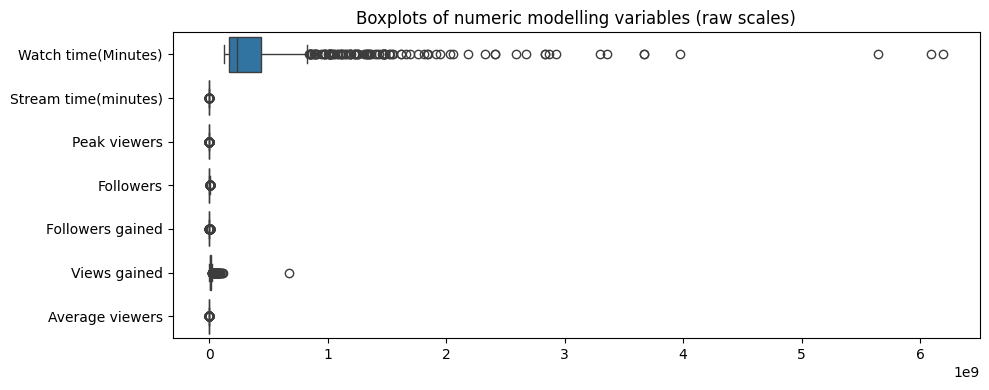

In [15]:
# IQR-based potential-outlier audit across the six predictors and target
iqr_columns = features + [target]
outlier_flags = pd.DataFrame(index=model_df.index)
for col in iqr_columns:
    q1 = model_df[col].quantile(0.25)
    q3 = model_df[col].quantile(0.75)
    iqr = q3 - q1
    outlier_flags[col] = (model_df[col] < q1 - 1.5 * iqr) | (model_df[col] > q3 + 1.5 * iqr)

any_iqr_outlier = outlier_flags.any(axis=1)
print(f"Rows flagged in at least one of the {len(iqr_columns)} numeric columns: {int(any_iqr_outlier.sum())} / {len(model_df)}")
print(f"Rows flagged by target Average viewers alone: {int(outlier_flags[target].sum())}")
display(outlier_flags.sum().sort_values(ascending=False).to_frame("Rows flagged by column"))

plt.figure(figsize=(10, 4))
sns.boxplot(data=model_df[features + [target]], orient="h")
plt.title("Boxplots of numeric modelling variables (raw scales)")
plt.tight_layout()
plt.show()

### Interpretation
The IQR rule flags observations outside 1.5 times the interquartile range from a variable's quartiles. A row is flagged if it is extreme in **at least one** of the seven numeric modelling columns. This is a screening rule, not proof of an error. Removing all flagged rows would remove potentially meaningful high-performing channels and change the population being modelled, so all observations are retained for the main models.

In [16]:
# Train-test split (reserve test set until final evaluation)
X = model_df[features]
y = model_df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 800
Test rows: 200


### Interpretation
The 80:20 split reserves 20% of the observations as a held-out test set. Models are fitted on the training data and evaluated on the same test observations to make the model comparison fair. Any scaling for Huber regression is fitted inside a pipeline, which ensures that the scaler learns from training folds/data only.

In [17]:
# Define models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=2, random_state=RANDOM_STATE
    ),
    "Huber Robust Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", HuberRegressor(epsilon=1.35, max_iter=2000))
    ]),
}

# Add XGBoost if installed
try:
    from xgboost import XGBRegressor
    models["XGBoost"] = XGBRegressor(
        n_estimators=300, learning_rate=0.04, max_depth=3,
        subsample=0.85, colsample_bytree=0.9, reg_lambda=1.0,
        objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1
    )
except ImportError:
    print("XGBoost is not installed; install it with: pip install xgboost")

def regression_metrics(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
    }

results = []
fitted_models = {}
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    fitted_models[name] = model
    predictions[name] = pred
    results.append({"Model": name, **regression_metrics(y_test, pred)})

results_df = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
display(results_df.round(3))

,Model,R2,RMSE
0,Huber Robust Regression,0.751,2305.799
1,XGBoost,0.644,2756.200
2,Linear Regression,0.409,3554.795
3,Random Forest,0.347,3736.101
4,Gradient Boosting,0.232,4050.464


### Interpretation
Compare test-set \(R^2\), MAE, median absolute error, and RMSE together. Higher \(R^2\) is better; lower error values are better. RMSE penalizes very large mistakes more strongly, while median absolute error describes a typical absolute error and is less influenced by a few extreme errors. Tree ensembles can capture nonlinear relationships and interactions, but they do not necessarily outperform robust linear methods on every dataset.

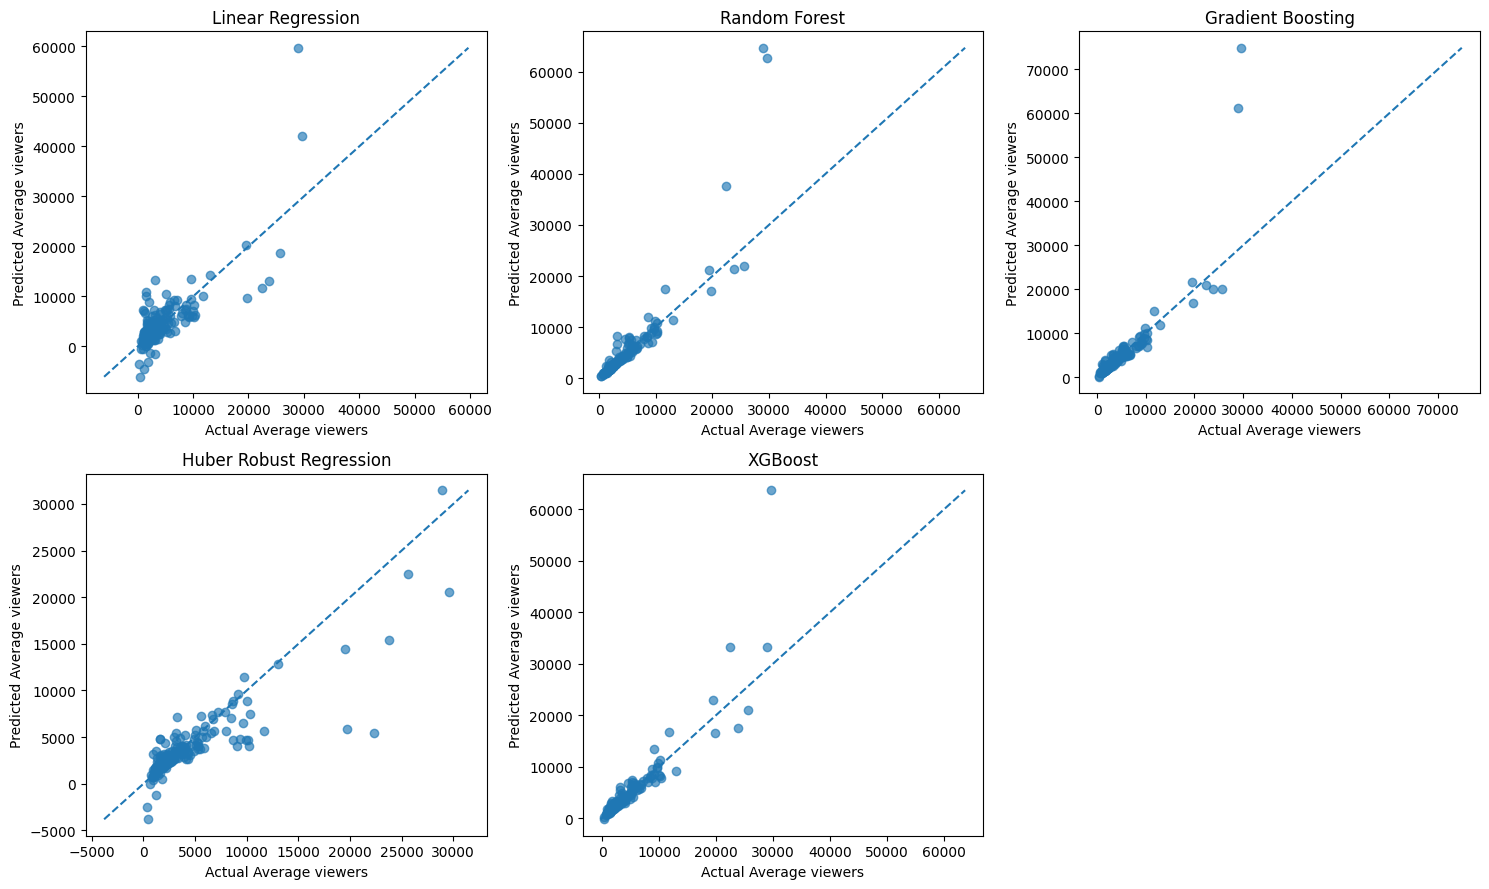

In [18]:
# Plot actual versus predicted values for each model
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()
for i, (name, pred) in enumerate(predictions.items()):
    ax = axes[i]
    ax.scatter(y_test, pred, alpha=0.65)
    low = min(float(y_test.min()), float(np.min(pred)))
    high = max(float(y_test.max()), float(np.max(pred)))
    ax.plot([low, high], [low, high], linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Actual Average viewers")
    ax.set_ylabel("Predicted Average viewers")
for j in range(len(predictions), len(axes)):
    axes[j].axis("off")
plt.tight_layout()
plt.show()

### Interpretation
Points closer to the diagonal line indicate more accurate predictions. Systematic underprediction at the high end would suggest that the model struggles to estimate the largest channels. Since the target distribution is skewed, inspect both the overall metrics and this plot rather than relying on a single score.

## Final Conclusion

This project involved exploratory data analysis, correlation analysis, and comparison of regression models for predicting average Twitch viewership. After establishing a baseline with Linear Regression, I evaluated Random Forest, Gradient Boosting, and XGBoost to capture potential nonlinear relationships.

The IQR method identified **288 potential outlier observations**. Rather than discarding these observations and potentially losing critical information about high-performing channels, I explored **Huber Robust Regression**, which retains all observations while reducing the influence of large residuals during model fitting.

Huber Robust Regression achieved a **test \(R^2\) of 0.751**, improving upon the baseline Linear Regression \(R^2\) of 0.409. This approach allowed me to account for extreme observations without removing potentially valuable data.